# LAB — Vision-Language Models: CLIP & LLaVA

**Module:** Artificial Intelligence / Generative AI  
**Level:** Phd Students  
**Environment:** Google Colab / Kaggle / Jupyter Notebook  
**Frameworks:** Python, PyTorch, Hugging Face Transformers

## Videos (Must see before Starting the Lab)
* https://www.youtube.com/watch?v=jXD6O93Ptks&t=6s
* https://www.youtube.com/watch?v=bK9ns4DkxQg&t=8s

## Objectives

This practical work introduces two important vision-language models:

- **CLIP**: image-text representation, similarity, zero-shot classification and image retrieval.
- **LLaVA**: multimodal image understanding and visual question answering.

At the end of the Lab, students should be able to:
1. Load a pretrained CLIP model.
2. Compare images and textual descriptions.
3. Perform zero-shot classification.
4. Evaluate classification accuracy.
5. Perform text-to-image retrieval.
6. Understand the architecture of LLaVA.
7. Run visual question answering.
8. Identify visual hallucinations.
9. Compare CLIP and LLaVA.
10. Build a small multimodal assistant.

> **Notebook organization:** Part I is the student statement. Part II contains the correction and reference implementations. Students should first complete the exercises without opening the correction section.

In [ ]:

import torch

print("GPU disponible :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU utilisé :", torch.cuda.get_device_name(0))


GPU disponible : True
GPU utilisé : Tesla T4


# Part I — LAB STATEMENT

## Exercise 1 — Installation and model loading

Install the required libraries and load `openai/clip-vit-base-patch32`.

### Questions

**Q1.** What is CLIP?  

**Q2.** What are its two main components?  

**Q3.** What is the role of `CLIPProcessor`?  

**Q4.** What is the role of `CLIPModel`?

###ANSWERS

**A1.** CLIP stands for Contrastive Language-Image Pretraining. It associates images and text in a shared representation space.

**A2.** CLIP consists of two main components: an image encoder and a text encoder. The image encoder extracts visual features from images, while the text encoder processes textual descriptions.

**A3.** CLIPProcessor prepares images and text in a format that CLIP can process, including resizing, normalization, and tokenization.

**A4.** CLIPModel contains the neural network that computes image and text representations and their similarity scores.

In [ ]:
# Run this cell first.
!pip install -q transformers torch torchvision pillow matplotlib pandas

In [ ]:
import torch
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from transformers import CLIPProcessor, CLIPModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

Device: cuda


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

## Exercise 2 — Load an image

Upload an image containing a recognizable object.

Examples: a cat, dog, car, horse, bird, airplane, person, etc.

### Questions

**Q5.** What is the size of the image?  
**Q6.** What type of data is stored in the PIL image object?

### ANSWERS

**A5.** The image size is 550 x 550 pixels (width, height)

**A6.** The PIL Image object stores pixel data representing the image. In RGB mode, each pixel contains three color channels : Red, Green, Blue, with values typically ranging from 0 to 255.

Image size: (550, 550)
Image mode: RGB


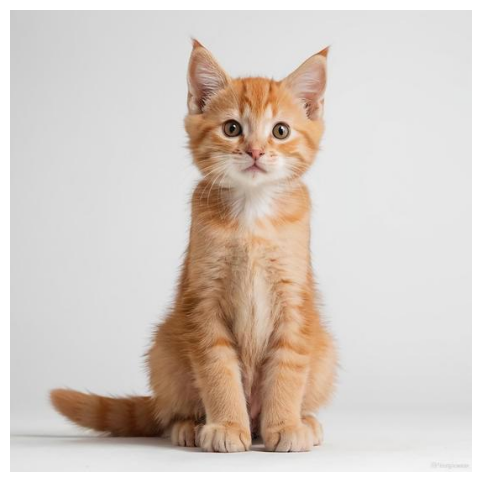

In [ ]:
# Upload an image in Google Colab/Jupyter and change the filename if necessary.
IMAGE_PATH = "chat.jpg"

image = Image.open(IMAGE_PATH).convert("RGB")
print("Image size:", image.size)
print("Image mode:", image.mode)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off");

## Exercise 3 — Image/Text similarity

Use the following textual descriptions:

```python
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]
```

Calculate the CLIP image-text scores and convert them to probabilities.

### Questions

**Q7.** Which description has the highest probability?  
**Q8.** Is it compatible with the actual image?  
**Q9.** Why can CLIP compare an image with a sentence?  
**Q10.** What does `softmax()` do?

### Answers

**A7.** The description "a photo of a cat" has the highest probability ( 98.86%).

**A8.** Yes. The image shows an orange kitten, and CLIP correctly identifies it as a cat.

**A9.** CLIP uses an image encorder and a text encorder to transform images and sentences into a shared embedding space, allowing it to measure thier  semantic similarity.

**A10.** The softmax() function converts similarity scores into normalized probabilities between 0 and 1, ensuring that their sum euqals 1.

In [ ]:
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]

inputs = processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True
)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

for text, probability in zip(texts, probs):
    print(f"{text:35s}: {probability.item():.4f}")

a photo of a cat                   : 0.9886
a photo of a dog                   : 0.0064
a photo of a car                   : 0.0001
a photo of a horse                 : 0.0006
a photo of a person                : 0.0044


## Exercise 4 — Zero-shot classification

Implement:

```python
def classify_image(image, classes):
    ...
```

The function must return the predicted class and its probability.

### Questions

**Q11.** What is zero-shot classification?  
**Q12.** Why is it not necessary to train a new classifier?  
**Q13.** What happens if the correct class is not included in the candidate classes?

### Answers

**A11.** Zero-shot classification allows a pretrained model to classify images into categories without additional training on those specific classes.

**A12.** CLIP has already learned relationships between images and text during pretraining. It can therefore compare an image with new textual class descriptions.

**A13.** CLIP selects the most similar class among the available candidates, even if none correctly describes the image.

In [ ]:

# STUDENT TASK
def classify_image(image, classes):

    # Convert class names into text descriptions
    texts = [f"a photo of a {c}" for c in classes]

    # Prepare the image and text inputs
    inputs = processor(
        text=texts,
        images=image,
        return_tensors="pt",
        padding=True
    )

    inputs = {k: v.to(device) for k, v in inputs.items()}

    # Run CLIP
    with torch.no_grad():
        outputs = model(**inputs)

    # Calculate probabilities
    probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

    # Find the class with the highest probability
    best_idx = probs.argmax().item()

    prediction = classes[best_idx]
    probability = probs[best_idx].item()

    return prediction, probability


classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

prediction, probability = classify_image(image, classes)

print("Prediction:", prediction)
print("Probability:", probability)


Prediction: cat
Probability: 0.9925347566604614


## Exercise 5 — Evaluate CLIP

Prepare at least 10 labeled images. For each image record:

- actual class;
- predicted class;
- probability;
- whether the prediction is correct.

Calculate:


$Accuracy = \frac{N_{correct}}{N_{total}}$


### Questions

**Q14.** What is the obtained accuracy?  
**Q15.** Which images are incorrectly classified?  
**Q16.** Give at least two possible reasons for the errors.

## Answers

**A14.** The obtained accuracy is 100%, with 10 correct predictions out of 10 images.

**A15.** No images were incorrectly classified in this experiment. All 10 images were correctly classified by CLIP.

**A16** No classification errors were observed in this experiment. However, potential classification errors could result from visual ambiguity, such as objects being partially hidden or appearing in complex backgrounds, and prompt sensitivity, where the wording of text descriptions influences CLIP's predictions.

Use the following format:

```python
dataset = [
    ("cat1.jpg", "cat"),
    ("cat2.jpg", "cat"),
    ...
]
```

In [ ]:
# STUDENT TASK
import pandas as pd
from PIL import Image

dataset = [
    ("cat1.jpg", "cat"),
    ("cat2.jpeg", "cat"),
    ("dog1.jpeg", "dog"),
    ("dog2.jpeg", "dog"),
    ("car1.jpeg", "car"),
    ("car2.jpeg", "car"),
    ("airplane1.jpg", "airplane"),
    ("airplane2.jpeg", "airplane"),
    ("horse1.jpeg", "horse"),
    ("bird1.jpeg", "bird")
]

classes = ["cat", "airplane", "dog", "car", "horse", "bird"]

results = []

for filename, actual_class in dataset:

    img = Image.open(filename).convert("RGB")

    predicted_class, probability = classify_image(img, classes)

    correct = predicted_class == actual_class

    results.append({
        "Image": filename,
        "Actual class": actual_class,
        "Predicted class": predicted_class,
        "Probability": round(probability, 4),
        "Correct": correct
    })

df = pd.DataFrame(results)

display(df)

accuracy = df["Correct"].mean() * 100

print(f"Accuracy: {accuracy:.2f}%")
print(f"Correct predictions: {df['Correct'].sum()}/{len(df)}")

,Image,Actual class,Predicted class,Probability,Correct
0,cat1.jpg,cat,cat,0.9925,True
1,cat2.jpeg,cat,cat,0.9950,True
2,dog1.jpeg,dog,dog,0.9921,True
3,dog2.jpeg,dog,dog,0.9972,True
4,car1.jpeg,car,car,0.9923,True
5,car2.jpeg,car,car,0.9973,True
6,airplane1.jpg,airplane,airplane,0.9983,True
7,airplane2.jpeg,airplane,airplane,0.9961,True
8,horse1.jpeg,horse,horse,0.9996,True
9,bird1.jpeg,bird,bird,0.9839,True


Accuracy: 100.00%
Correct predictions: 10/10


In [ ]:
# STUDENT TASK — Exercise 6

prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]

# Prepare inputs
inputs = processor(
    text=prompts,
    images=image,
    return_tensors="pt",
    padding=True
)

inputs = {k: v.to(device) for k, v in inputs.items()}

# Run CLIP
with torch.no_grad():
    outputs = model(**inputs)

# Calculate similarity scores
scores = outputs.logits_per_image[0].cpu()

# Display results
for prompt, score in zip(prompts, scores):
    print(f"{prompt:40s}: {score.item():.4f}")

# Identify the highest score
best_idx = scores.argmax().item()

print("\nBest prompt:", prompts[best_idx])
print("Highest score:", round(scores[best_idx].item(), 4))

a cat                                   : 26.1576
a photo of a cat                        : 27.9826
a photograph showing a cat              : 28.2993
an image containing a cat               : 27.1280
a domestic animal called a cat          : 27.1881

Best prompt: a photograph showing a cat
Highest score: 28.2993


### Answers

**A17.** No, the similarity scores are different for each prompt, even though all five descriptions refer to the same object (a cat).  

**A18.** The prompt "a photograph showing a cat" gives the highest similarity score of 28.2993.

**A19.** This experiment demonstrates that CLIP is sensitive to prompt formulation. Different descriptions of the same object produce different similarity scores. The choice of words and sentence structure can influence how well CLIP matches text with an image.

# Part B — CLIP Image Retrieval

## Exercise 7 — Build an image database

Create a folder containing at least 20 images.

The images can represent animals, vehicles, people, buildings, landscapes, food or sports.

Calculate and store a normalized CLIP embedding for every image.

## Exercise 8 — Text-to-image retrieval

Use the query:

```text
"a person playing football"
```

Calculate its text embedding, compare it with all image embeddings, and display the five most similar images.

### Questions

**Q20.** What is the most similar image?  
**Q21.** Is it semantically relevant?  
**Q22.** Why does this method not require image labels?  
**Q23.** Give one real-world application of semantic image retrieval.

In [ ]:

import os

IMAGE_DIR = "/content"

image_paths = sorted([
    os.path.join(IMAGE_DIR, f)
    for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

print("Total images:", len(image_paths))

for path in image_paths:
    print(path)


Total images: 20
/content/Food1.jpeg
/content/Food2.jpeg
/content/Football players1.jpeg
/content/Football players2.jpeg
/content/Football players3.jpeg
/content/Football players4.jpeg
/content/Football players5.jpeg
/content/Landscapes1.jpeg
/content/Landscapes2.jpeg
/content/Landscapes3.jpeg
/content/airplane1.jpg
/content/airplane2.jpeg
/content/bird1.jpeg
/content/car1.jpeg
/content/car2.jpeg
/content/cat1.jpg
/content/cat2.jpeg
/content/dog1.jpeg
/content/dog2.jpeg
/content/horse1.jpeg


Image embeddings shape: torch.Size([20, 512])
Rank 1: /content/Football players1.jpeg | Similarity: 0.2676
Rank 2: /content/Football players4.jpeg | Similarity: 0.2623
Rank 3: /content/Football players2.jpeg | Similarity: 0.2469
Rank 4: /content/Football players3.jpeg | Similarity: 0.2468
Rank 5: /content/Football players5.jpeg | Similarity: 0.2416


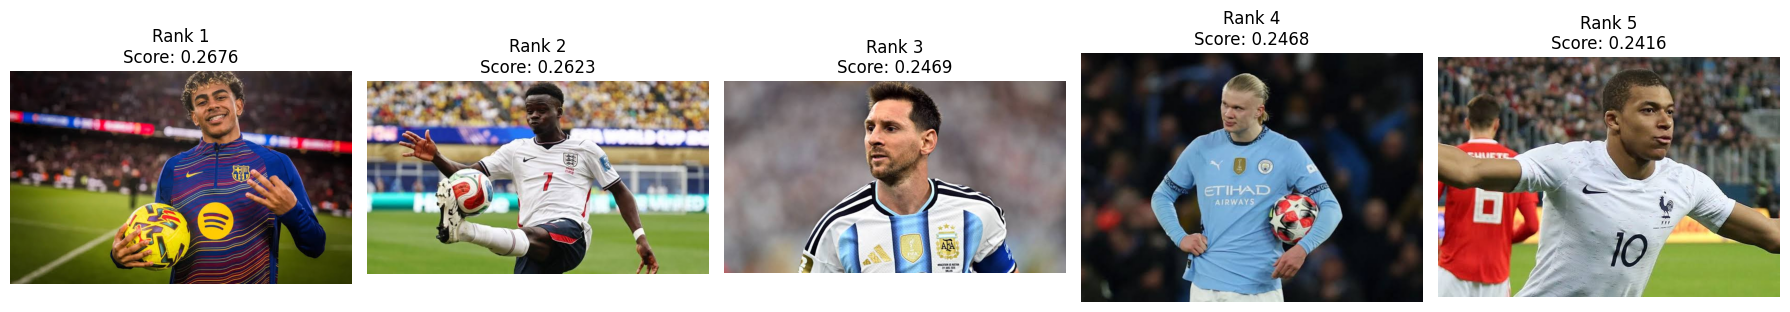

In [ ]:

# STUDENT TASK — Exercises 7 & 8

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

IMAGE_DIR = "/content"
QUERY = "a person playing football"

# 1. Load the 20 images
images = [
    Image.open(path).convert("RGB")
    for path in image_paths
]

# 2. Compute image embeddings
inputs = processor(
    images=images,
    return_tensors="pt"
)

with torch.no_grad():
    image_embeddings = model.get_image_features(
        pixel_values=inputs["pixel_values"].to(device)
    )

if hasattr(image_embeddings, "pooler_output"):
    image_embeddings = image_embeddings.pooler_output

# Normalize embeddings
image_embeddings = F.normalize(
    image_embeddings, p=2, dim=-1
)

print("Image embeddings shape:", image_embeddings.shape)

# 3. Compute query embedding
text_inputs = processor(
    text=[QUERY],
    return_tensors="pt",
    padding=True
)

text_inputs = {
    k: v.to(device) for k, v in text_inputs.items()
}

with torch.no_grad():
    text_embedding = model.get_text_features(**text_inputs)

if hasattr(text_embedding, "pooler_output"):
    text_embedding = text_embedding.pooler_output

text_embedding = F.normalize(
    text_embedding, p=2, dim=-1
)

# 4. Cosine similarity
similarities = (
    image_embeddings @ text_embedding.T
).squeeze(1)

# 5. Top-5 retrieval
top_scores, top_indices = torch.topk(
    similarities, k=5
)

# Display results
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for rank, (score, idx) in enumerate(
    zip(top_scores, top_indices)
):
    i = idx.item()

    axes[rank].imshow(images[i])
    axes[rank].set_title(
        f"Rank {rank+1}\nScore: {score.item():.4f}"
    )
    axes[rank].axis("off")

    print(
        f"Rank {rank+1}: {image_paths[i]} "
        f"| Similarity: {score.item():.4f}"
    )

plt.tight_layout()
plt.show()

## ANSWERS

**A20.** The most similar image is " Football players1.jpeg", with a cosine similarity score of 0.2676

**A21.** Yes. The retrieved image shows a football player holding a ball on a football field. It's semantically relevent to the query "a person playing football", although it does not necessarily depict active gameplay.

**A22.** CLIP does not require image labels because it compares text and image embeddings in a shared semantic space. Images are retrieved based on similarity rather than predefined categories.

**A23.** One application is industrial image retrieval, where engineers can search image databases for equipment, components, or manufacturing activities using natural-language queries.

# Part C — LLaVA

## Exercise 9 — Architecture

Complete:

```text
Image
  |
  v
CLIP Vision Encoder
  |
  v
Project layer
  |
  v
Language Model
  |
  v
Text Response
```

### Questions

**Q24.** What is the role of the vision encoder?  
**Q25.** Why is a projection layer required?  
**Q26.** What is the role of the language model?

## Answers

**A24.** The vision encoder extracts meaningful visual features from the input image and converts them into numerical representations ( visual embeddings) that can be processed by the multimodal system.

**A25.** The projection layer maps the visual features produced by the vision encoder into the embedding space expected by the language model, enabling the integration of visual information with text.

**A26.** The language model processes the visual information together with the user's text instructions to understand the context and generate meaningful natural-language responses.

## Exercise 10 — Run LLaVA

Use a LLaVA-compatible model appropriate for your available GPU.

Give the model an image and ask:

1. What is happening in this image?
2. How many people are visible?
3. What objects can you identify?
4. Describe the image in detail.

Record the answers.

In [1]:
import torch
import transformers
import accelerate
import bitsandbytes

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Accelerate:", accelerate.__version__)
print("BitsAndBytes:", bitsandbytes.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch: 2.11.0+cu130
Transformers: 5.20.1
Accelerate: 1.15.0
BitsAndBytes: 0.50.2
GPU available: True


In [2]:

from transformers import (
    AutoProcessor,
    LlavaForConditionalGeneration,
    BitsAndBytesConfig
)

print("LLaVA imports successful!")


LLaVA imports successful!


In [3]:
import gc
import torch

if "model" in globals():
    del model

if "image_embeddings" in globals():
    del image_embeddings

if "text_embedding" in globals():
    del text_embedding

gc.collect()
torch.cuda.empty_cache()

print("GPU memory cleaned.")


GPU memory cleaned.


In [4]:
!pip install -q -U transformers accelerate bitsandbytes

In [5]:
import torch
from transformers import (
    AutoProcessor,
    LlavaForConditionalGeneration,
    BitsAndBytesConfig
)

MODEL_ID = "llava-hf/llava-1.5-7b-hf"

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16
)

processor_llava = AutoProcessor.from_pretrained(
    MODEL_ID
)

llava = LlavaForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=quantization_config,
    device_map="auto",
    torch_dtype=torch.float16
)

llava.eval()

print("LLaVA loaded successfully!")

model.safetensors.index.json:   0%|          | 0.00/70.1k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

LLaVA loaded successfully!


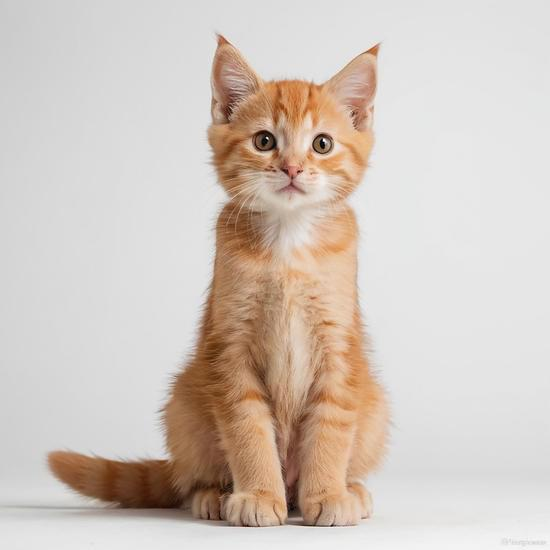

In [10]:
from PIL import Image

image_llava = Image.open(
    "/content/cat1.jpg"
).convert("RGB")

display(image_llava)

In [11]:
import torch

questions = [
    "What is happening in this image?",
    "How many people are visible?",
    "What objects can you identify?",
    "Describe the image in detail."
]

answers = []

for question in questions:
    prompt = f"USER: <image>\n{question} ASSISTANT:"

    inputs = processor_llava(
        text=prompt,
        images=image_llava,
        return_tensors="pt"
    ).to("cuda")

    with torch.inference_mode():
        output = llava.generate(
            **inputs,
            max_new_tokens=150,
            do_sample=False
        )

    generated_tokens = output[
        :, inputs["input_ids"].shape[1]:
    ]

    answer = processor_llava.batch_decode(
        generated_tokens,
        skip_special_tokens=True
    )[0].strip()

    answers.append(answer)

    print("\nQuestion:", question)
    print("Answer:", answer)
    print("-" * 50)


Question: What is happening in this image?
Answer: In the image, a small orange and white kitten is sitting on a white surface, possibly a table or a counter. The kitten appears to be looking at the camera, capturing a cute and curious moment.
--------------------------------------------------

Question: How many people are visible?
Answer: There are no people visible in the image. The focus is on the orange and white kitten.
--------------------------------------------------

Question: What objects can you identify?
Answer: In the image, you can identify a small orange and white kitten sitting on a white surface. The kitten is the main subject of the photo, and it appears to be looking at the camera.
--------------------------------------------------

Question: Describe the image in detail.
Answer: The image features a small, orange and white kitten sitting on a white surface. The kitten appears to be looking at the camera, possibly posing for a picture. The kitten is positioned in t

In [12]:
import pandas as pd

df_answers = pd.DataFrame({
    "Question": questions,
    "LLaVA Response": answers
})


pd.set_option("display.max_colwidth", None)
display(df_answers)

,Question,LLaVA Response
0,What is happening in this image?,"In the image, a small orange and white kitten is sitting on a white surface, possibly a table or a counter. The kitten appears to be looking at the camera, capturing a cute and curious moment."
1,How many people are visible?,There are no people visible in the image. The focus is on the orange and white kitten.
2,What objects can you identify?,"In the image, you can identify a small orange and white kitten sitting on a white surface. The kitten is the main subject of the photo, and it appears to be looking at the camera."
3,Describe the image in detail.,"The image features a small, orange and white kitten sitting on a white surface. The kitten appears to be looking at the camera, possibly posing for a picture. The kitten is positioned in the center of the image, occupying a significant portion of the frame."


## Exercise 11 — Visual Question Answering

Choose five images. For each image ask five questions.

Example:

1. How many people are visible?
2. What objects can you see?
3. Where are the people?
4. What are they doing?
5. What is visible on the board?

Create a table containing:

| Image | Question | LLaVA Answer | Human Evaluation |
|---|---|---|---|

Calculate VQA accuracy:

\[
Accuracy = \frac{CorrectAnswers}{TotalQuestions}
\]

### Questions

**Q27.** What is the VQA accuracy?  
**Q28.** Which types of questions are difficult for LLaVA?

### Answers

**A27.** The VQA accuracy obtained through human evaluation is 84%, with 21 correct answers out of 25 questions. The rule-based automatic evaluation achieved 88% (22 out of 25). The difference comes from an additional error identified during visual verification.

**A28.** LLaVA may struggle with precise visual details and complex scene interpretation. In our experiment, the model hallucinated birds in the football and airplane images, provided an inaccurate description of the car's location, and generated a contradictory answer about the food image.

In [13]:
import os
import torch
import pandas as pd
from PIL import Image

image_files = [
    "cat1.jpg",
    "car1.jpeg",
    "Football players1.jpeg",
    "airplane1.jpg",
    "Food1.jpeg"
]

questions_vqa = [
    "How many people are visible?",
    "What objects or animals can you see?",
    "Where is the main subject located?",
    "What is the main subject doing?",
    "Describe the most noticeable visual detail."
]

print("Number of images:", len(image_files))
print("Total questions:", len(image_files) * len(questions_vqa))

for filename in image_files:
    assert os.path.exists(
        f"/content/{filename}"
    ), f"Missing image: {filename}"

Number of images: 5
Total questions: 25


In [14]:
results_vqa = []

for filename in image_files:

    image_path = f"/content/{filename}"
    current_image = Image.open(image_path).convert("RGB")

    print("\nProcessing:", filename)

    for question in questions_vqa:

        prompt = f"USER: <image>\n{question} ASSISTANT:"

        inputs = processor_llava(
            text=prompt,
            images=current_image,
            return_tensors="pt"
        ).to("cuda")

        with torch.inference_mode():
            output = llava.generate(
                **inputs,
                max_new_tokens=100,
                do_sample=False
            )

        generated_tokens = output[
            :, inputs["input_ids"].shape[1]:
        ]

        answer = processor_llava.batch_decode(
            generated_tokens,
            skip_special_tokens=True
        )[0].strip()

        results_vqa.append({
            "Image": filename,
            "Question": question,
            "LLaVA Answer": answer,
            "Human Evaluation": ""
        })

        print("Q:", question)
        print("A:", answer)

df_vqa = pd.DataFrame(results_vqa)

display(df_vqa)


Processing: cat1.jpg
Q: How many people are visible?
A: There are no people visible in the image. The focus is on the orange and white kitten.
Q: What objects or animals can you see?
A: In the image, you can see a small orange and white kitten sitting on a white surface.
Q: Where is the main subject located?
A: The main subject, a small orange kitten, is located on a white background.
Q: What is the main subject doing?
A: The main subject, a small orange kitten, is sitting on a white surface.
Q: Describe the most noticeable visual detail.
A: The most noticeable visual detail in the image is the orange and white cat sitting on the ground. The cat is looking at the camera, and its fur appears to be a mix of orange and white colors. The cat's position and expression make it the focal point of the image.

Processing: car1.jpeg
Q: How many people are visible?
A: There are no people visible in the image.
Q: What objects or animals can you see?
A: In the image, you can see a red sports car p

,Image,Question,LLaVA Answer,Human Evaluation
0,cat1.jpg,How many people are visible?,There are no people visible in the image. The focus is on the orange and white kitten.,
1,cat1.jpg,What objects or animals can you see?,"In the image, you can see a small orange and white kitten sitting on a white surface.",
2,cat1.jpg,Where is the main subject located?,"The main subject, a small orange kitten, is located on a white background.",
3,cat1.jpg,What is the main subject doing?,"The main subject, a small orange kitten, is sitting on a white surface.",
4,cat1.jpg,Describe the most noticeable visual detail.,"The most noticeable visual detail in the image is the orange and white cat sitting on the ground. The cat is looking at the camera, and its fur appears to be a mix of orange and white colors. The cat's position and expression make it the focal point of the image.",
5,car1.jpeg,How many people are visible?,There are no people visible in the image.,
6,car1.jpeg,What objects or animals can you see?,"In the image, you can see a red sports car parked on the street, and there are trees in the background.",
7,car1.jpeg,Where is the main subject located?,"The main subject, a red sports car, is located on a street near a body of water.",
8,car1.jpeg,What is the main subject doing?,"The main subject, a red sports car, is parked on the side of the road.",
9,car1.jpeg,Describe the most noticeable visual detail.,"The most noticeable visual detail in the image is the red sports car parked on the street. The car is a striking red color, which makes it stand out against the background. The car is parked on the side of the road, and it appears to be a sleek and modern design, possibly a sports car or a luxury vehicle.",


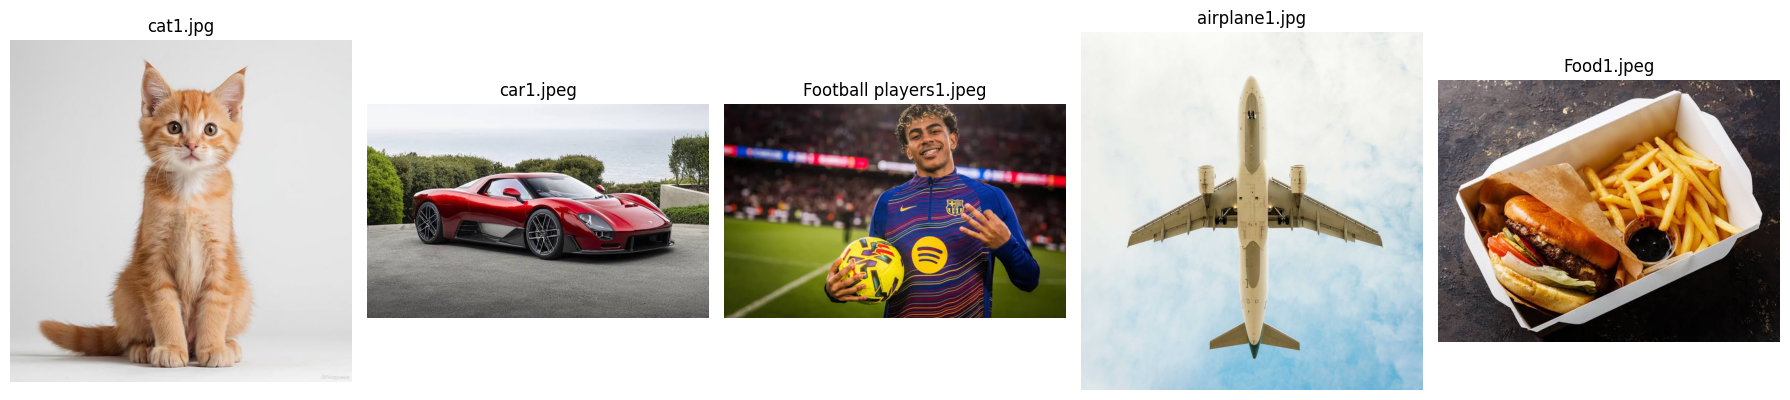

In [15]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, filename in zip(axes, image_files):
    img = Image.open(f"/content/{filename}").convert("RGB")
    ax.imshow(img)
    ax.set_title(filename)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [55]:
# Exercise 11 — Automatic and Human Evaluation

import pandas as pd

# 1. Automatic evaluation
def automatic_evaluation(row):
    answer = str(row["LLaVA Answer"]).lower()
    image = row["Image"].lower()

    # Known hallucinations
    if "football" in image and "bird" in answer:
        return 0

    if "airplane" in image and "bird" in answer:
        return 0

    # Contradictory answer in food image
    if "food" in image and "no animals or objects" in answer:
        return 0

    # No error detected by these rules
    return 1


df_vqa["Automatic Evaluation"] = df_vqa.apply(
    automatic_evaluation, axis=1
)

# 2. Human evaluation based on visual verification
# 1 = Correct answer
# 0 = Incorrect answer

incorrect_indices = [8, 11, 16, 21]

df_vqa["Human Evaluation"] = 1
df_vqa.loc[incorrect_indices, "Human Evaluation"] = 0

# 3. Calculate accuracy
automatic_accuracy = df_vqa["Automatic Evaluation"].mean() * 100
human_accuracy = df_vqa["Human Evaluation"].mean() * 100

# 4. Display final evaluation table
display(df_vqa[
    [
        "Image",
        "Question",
        "LLaVA Answer",
        "Automatic Evaluation",
        "Human Evaluation"
    ]
])

# 5. Display evaluation results
print("===== VQA EVALUATION RESULTS =====")
print(f"Total questions: {len(df_vqa)}")
print(f"Automatic Evaluation Accuracy: {automatic_accuracy:.2f}%")
print(f"Human Evaluation Accuracy: {human_accuracy:.2f}%")
print(f"Correct human-evaluated answers: {df_vqa['Human Evaluation'].sum()}/{len(df_vqa)}")
print(f"Incorrect human-evaluated answers: {(df_vqa['Human Evaluation'] == 0).sum()}")

,Image,Question,LLaVA Answer,Automatic Evaluation,Human Evaluation
0,cat1.jpg,How many people are visible?,There are no people visible in the image. The focus is on the orange and white kitten.,1,1
1,cat1.jpg,What objects or animals can you see?,"In the image, you can see a small orange and white kitten sitting on a white surface.",1,1
2,cat1.jpg,Where is the main subject located?,"The main subject, a small orange kitten, is located on a white background.",1,1
3,cat1.jpg,What is the main subject doing?,"The main subject, a small orange kitten, is sitting on a white surface.",1,1
4,cat1.jpg,Describe the most noticeable visual detail.,"The most noticeable visual detail in the image is the orange and white cat sitting on the ground. The cat is looking at the camera, and its fur appears to be a mix of orange and white colors. The cat's position and expression make it the focal point of the image.",1,1
5,car1.jpeg,How many people are visible?,There are no people visible in the image.,1,1
6,car1.jpeg,What objects or animals can you see?,"In the image, you can see a red sports car parked on the street, and there are trees in the background.",1,1
7,car1.jpeg,Where is the main subject located?,"The main subject, a red sports car, is located on a street near a body of water.",1,1
8,car1.jpeg,What is the main subject doing?,"The main subject, a red sports car, is parked on the side of the road.",1,0
9,car1.jpeg,Describe the most noticeable visual detail.,"The most noticeable visual detail in the image is the red sports car parked on the street. The car is a striking red color, which makes it stand out against the background. The car is parked on the side of the road, and it appears to be a sleek and modern design, possibly a sports car or a luxury vehicle.",1,1


===== VQA EVALUATION RESULTS =====
Total questions: 25
Automatic Evaluation Accuracy: 88.00%
Human Evaluation Accuracy: 84.00%
Correct human-evaluated answers: 21/25
Incorrect human-evaluated answers: 4


In [25]:
import torch

print("GPU available:", torch.cuda.is_available())
print("LLaVA model loaded:", "llava" in globals())
print("LLaVA processor loaded:", "processor_llava" in globals())
print("VQA results available:", "df_vqa" in globals())

GPU available: True
LLaVA model loaded: True
LLaVA processor loaded: True
VQA results available: True


In [26]:
print("LLaVA model:", "llava" in globals())
print("Processor:", "processor_llava" in globals())
print("GPU:", torch.cuda.is_available())

LLaVA model: True
Processor: True
GPU: True


## Exercise 12 — Hallucination

Choose an image that does **not** contain a bicycle.

Ask:

> Is there a bicycle in this image?

Then ask:

> What color is the bicycle?

Then ask:

> Where is the bicycle located?

### Questions

**Q29.** Does the bicycle actually exist?  
**Q30.** Did LLaVA invent information?  
**Q31.** What is a visual hallucination?  
**Q32.** Why can a multimodal model hallucinate?

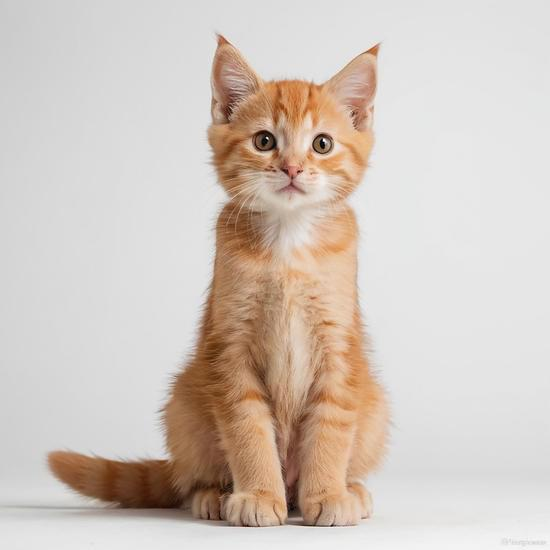

In [27]:
from PIL import Image
from IPython.display import display

image_hallucination = Image.open("/content/cat1.jpg").convert("RGB")
display(image_hallucination)

In [28]:
questions_hallucination = [
    "Is there a bicycle in this image?",
    "What color is the bicycle?",
    "Where is the bicycle located?"
]

for question in questions_hallucination:
    prompt = f"USER: <image>\n{question} ASSISTANT:"

    inputs = processor_llava(
        text=prompt,
        images=image_hallucination,
        return_tensors="pt"
    ).to("cuda")

    with torch.inference_mode():
        output = llava.generate(
            **inputs,
            max_new_tokens=100,
            do_sample=False
        )

    generated_tokens = output[:, inputs["input_ids"].shape[1]:]

    answer = processor_llava.batch_decode(
        generated_tokens,
        skip_special_tokens=True
    )[0].strip()

    print("Question:", question)
    print("LLaVA Answer:", answer)
    print("-" * 50)

Question: Is there a bicycle in this image?
LLaVA Answer: No, there is no bicycle in this image. The image features a small orange kitten sitting on a white surface.
--------------------------------------------------
Question: What color is the bicycle?
LLaVA Answer: The bicycle is orange.
--------------------------------------------------
Question: Where is the bicycle located?
LLaVA Answer: The bicycle is located in the background of the image, behind the orange and white cat.
--------------------------------------------------


### ANSWERS
 **A29.** No, there is no bicycle in the image. The image only shows an orange and white kitten.

 **A30.** Yes. LLaVA invented an orange bicycle and claimed it was located behind the cat, even though no bicycle exists in the image.

 **A31.** A visual hallucination occurs when an AI model generates information about objects or details that are not actually present in an image.

 **A32.** A multimodal model can hallucinate because it relies on learned patterns and predictions. It may generate incorrect information when questions contain false assumptions.

# Part D — CLIP vs LLaVA

## Exercise 13 — Comparative experiment

Use the same image with both models.

### CLIP

Compare:

- a photo of a cat
- a photo of a dog
- a photo of a horse

### LLaVA

Ask:

> What animal is present in the image? Describe its appearance.

Complete:

| Property | CLIP | LLaVA |
|---|---|---|
| Input |Image +  Text | Image + Question|
| Main output | Similarity scores | Generated text|
| Zero-shot classification | Yes| Possible|
| Image retrieval | Yes| Not primarily|
| Text generation | No| Yes|
| VQA | Not directly| Yes|
| Open-ended response | No| Yes|

### Questions

**Q33.** Which model is better suited to image classification?  
**Q34.** Which model is better for image description?  
**Q35.** Which model is better for visual question answering?  
**Q36.** Explain the fundamental difference between CLIP and LLaVA.

In [30]:
import torch
from PIL import Image

image = Image.open("/content/cat1.jpg").convert("RGB")

labels = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a horse"
]

# Check existing CLIP variables
print([name for name in globals() if "clip" in name.lower()])

[]


In [31]:
from transformers import CLIPModel, CLIPProcessor
import torch

CLIP_MODEL_ID = "openai/clip-vit-base-patch32"

processor_clip = CLIPProcessor.from_pretrained(CLIP_MODEL_ID)

model_clip = CLIPModel.from_pretrained(
    CLIP_MODEL_ID
).to("cpu")

model_clip.eval()

print("CLIP loaded successfully!")

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP loaded successfully!


In [32]:
inputs_clip = processor_clip(
    text=labels,
    images=image,
    return_tensors="pt",
    padding=True
)

with torch.no_grad():
    outputs_clip = model_clip(**inputs_clip)

scores = outputs_clip.logits_per_image.softmax(dim=1)[0]

for label, score in zip(labels, scores):
    print(f"{label}: {score.item() * 100:.2f}%")

print("\nPredicted class:", labels[scores.argmax().item()])

a photo of a cat: 99.30%
a photo of a dog: 0.64%
a photo of a horse: 0.06%

Predicted class: a photo of a cat


In [33]:
question = "What animal is present in the image? Describe its appearance."

prompt = f"USER: <image>\n{question} ASSISTANT:"

inputs = processor_llava(
    text=prompt,
    images=image,
    return_tensors="pt"
).to("cuda")

with torch.inference_mode():
    output = llava.generate(
        **inputs,
        max_new_tokens=150,
        do_sample=False
    )

generated_tokens = output[:, inputs["input_ids"].shape[1]:]

answer = processor_llava.batch_decode(
    generated_tokens,
    skip_special_tokens=True
)[0].strip()

print("Question:", question)
print("LLaVA Answer:", answer)

Question: What animal is present in the image? Describe its appearance.
LLaVA Answer: A small orange and white kitten is present in the image.


**Q33. Which model is better suited to image classification?**

CLIP is better suited to image classification because it compares images with text labels using similarity scores.

**Q34. Which model is better for image description?**

LLaVA is better for image description because it generates natural language descriptions of images.

**Q35. Which model is better for visual question answering?**

LLaVA is better for visual question answering because it can understand images and answer questions about their content.

**Q36. Explain the fundamental difference between CLIP and LLaVA.**

CLIP measures similarity between images and text, while LLaVA generates natural language responses based on visual information.

# Final Mini-Project

Develop a small **Multimodal Image Assistant**.

The application receives:

```text
Image + Question
```

and returns an answer.

### Basic architecture

```text
             IMAGE
               |
               v
        +--------------+
        | Vision Model |
        +------+-------+
               |
               v
        Visual Features
               |
               v
QUESTION ---> LLaVA
               |
               v
             ANSWER
```

### Bonus

Combine CLIP retrieval with LLaVA:

```text
User Query
    |
    v
   CLIP
    |
    v
Top-K Images
    |
    v
  LLaVA
    |
    v
Explanation
```

### Deliverables

1. Jupyter Notebook.
2. Code and outputs for every experiment.
3. CLIP classification accuracy.
4. Top-5 retrieval results.
5. LLaVA VQA results.
6. At least one hallucination example.
7. CLIP/LLaVA comparison.
8. Mini-project.
9. Short conclusion.

# Final Mini-Project — Multimodal Image Assistant

## Objective
Develop an independent multimodal assistant that accepts
an image and a question and generates a natural language answer.

## Model
LLaVA 1.5 7B with 4-bit quantization.

In [37]:
import torch
from PIL import Image
from transformers import (
    AutoProcessor,
    LlavaForConditionalGeneration,
    BitsAndBytesConfig
)

# Mini-project model configuration
PROJECT_MODEL_ID = "llava-hf/llava-1.5-7b-hf"

project_quantization = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16
)

# Load processor
project_processor = AutoProcessor.from_pretrained(
    PROJECT_MODEL_ID
)

# Load LLaVA model
project_model = LlavaForConditionalGeneration.from_pretrained(
    PROJECT_MODEL_ID,
    quantization_config=project_quantization,
    device_map="auto",
    torch_dtype=torch.float16
)

project_model.eval()

print("Mini-project model loaded successfully!")

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

Mini-project model loaded successfully!


In [38]:
# Multimodal Image Assistant

def image_assistant(image_path, question):

    # Load image
    image = Image.open(image_path).convert("RGB")

    # Prepare prompt
    prompt = f"USER: <image>\n{question} ASSISTANT:"

    # Process image and question
    inputs = project_processor(
        text=prompt,
        images=image,
        return_tensors="pt"
    ).to("cuda")

    # Generate answer
    with torch.inference_mode():
        output = project_model.generate(
            **inputs,
            max_new_tokens=150,
            do_sample=False
        )

    # Decode generated answer
    generated_tokens = output[
        :, inputs["input_ids"].shape[1]:
    ]

    answer = project_processor.batch_decode(
        generated_tokens,
        skip_special_tokens=True
    )[0].strip()

    return answer


print("Multimodal Image Assistant is ready!")

Multimodal Image Assistant is ready!


In [39]:
# Test the Multimodal Image Assistant

image_path = "/content/cat1.jpg"
question = "What animal is present in this image?"

answer = image_assistant(image_path, question)

print("Image:", image_path)
print("Question:", question)
print("Assistant Answer:", answer)

Image: /content/cat1.jpg
Question: What animal is present in this image?
Assistant Answer: A kitten is present in this image.


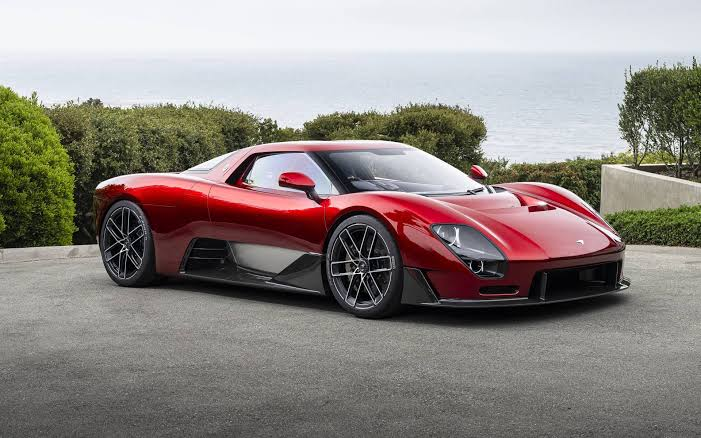

Question: Describe what you see in this image.
Assistant Answer: The image features a red sports car parked on a street near a body of water. The car is a sleek and modern design, with a windshield and a steering wheel visible. The car is positioned in the foreground, occupying a significant portion of the scene.

In addition to the sports car, there are two people in the background, one closer to the left side of the image and the other further to the right. The presence of these individuals suggests that they might be admiring the sports car or simply passing by.


In [41]:
# Test 2 — Car Image

image_path = "/content/car1.jpeg"
question = "Describe what you see in this image."

display(Image.open(image_path))

answer = image_assistant(image_path, question)

print("Question:", question)
print("Assistant Answer:", answer)

### Mini-Project Conclusion

In this mini-project, a multimodal image assistant was developed using the LLaVA model. The assistant takes an image and a text question as input and generates a natural language answer.

The assistant was successfully tested on two images: a kitten and a sports car. The model correctly identified the kitten and described the main elements of the car image. However, it also generated some inaccurate visual details, illustrating the risk of hallucinations in multimodal models.

Overall, the experiment demonstrates the ability of LLaVA to perform visual question answering and image description, while highlighting the importance of verifying generated responses.